In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

# Analisis inicial del flujo vehicular en el circuito

In [2]:
VV2024_semanal = pd.read_csv('volumen_vehicular_2024_detalle_semanal.csv')

In [3]:
circuito = {
    'ENTRE RIOS AV. 678':     'norte',
    'BELGRANO AV. 324':       'este',
    'PASEO COLON AV. 753':    'sur',
    'INDEPENDENCIA AV. 1784': 'oeste',
}
dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

VV_8am = VV2024_semanal[
    (VV2024_semanal['ubicacion_conteo'].map(circuito) == VV2024_semanal['sentido_circulacion_conteo']) &
    (VV2024_semanal['franja_horaria_conteo'] == 8) &
    VV2024_semanal['dia_semana_conteo'].isin(dias)
].copy()

In [4]:
por_dia = (VV_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())

In [5]:
prom_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))
prom_8am

,ubicacion_conteo,sentido_circulacion_conteo,cuarto_hora_conteo,vehiculos_promedio
0,BELGRANO AV. 324,este,1,14.0
1,BELGRANO AV. 324,este,2,7.0
2,BELGRANO AV. 324,este,3,32.6
3,BELGRANO AV. 324,este,4,96.4
4,ENTRE RIOS AV. 678,norte,1,57.6
5,ENTRE RIOS AV. 678,norte,2,59.2
6,ENTRE RIOS AV. 678,norte,3,68.2
7,ENTRE RIOS AV. 678,norte,4,67.8
8,INDEPENDENCIA AV. 1784,oeste,1,233.0
9,INDEPENDENCIA AV. 1784,oeste,2,242.0


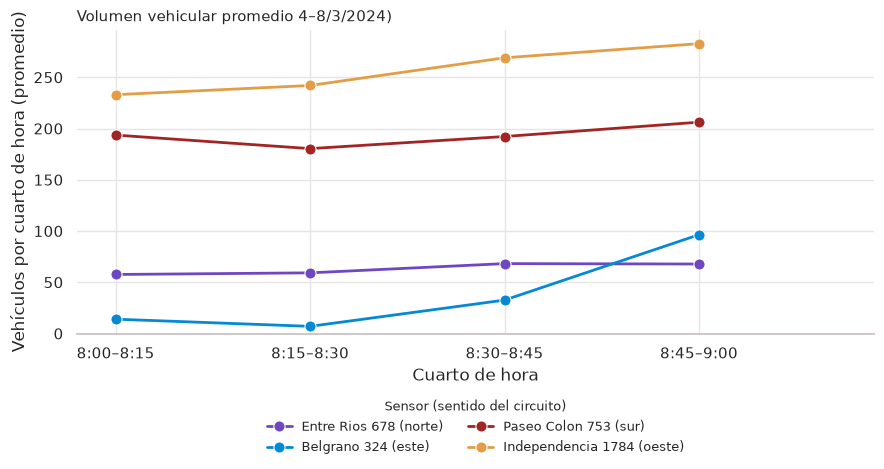

In [6]:
# etiquetas legibles
cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_8am['cuarto'] = prom_8am['cuarto_hora_conteo'].map(cuartos)
prom_8am['sensor'] = (prom_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title()+ ' (' + prom_8am['sentido_circulacion_conteo'] + ')')

orden = ['Entre Rios 678 (norte)', 'Belgrano 324 (este)', 'Paseo Colon 753 (sur)', 'Independencia 1784 (oeste)']
colores = dict(zip(orden, ["#7047c2", "#0489d5", "#a22525", "#e39e45"]))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_8am.loc[(prom_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Volumen vehicular promedio 4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Simulaciones

In [7]:
circuito = pd.read_csv('semaforos_circuito_distancias.csv')

In [8]:
from scipy.integrate import solve_ivp      # resuelve ecuaciones diferenciales

# funciones de simulación (copiadas de Colab_investigathon)

def condiciones_iniciales_random(n, semilla=None):
    # Devuelve n fases al azar, uniformes entre 0 y 2*pi.
    rng = np.random.default_rng(semilla)    # generador de números aleatorios
    return rng.uniform(-np.pi, np.pi, n)


def ecuaciones(t, phi, A, K, Delta, omega=0.0):
    # dphi_i/dt = omega - dV/dphi_i
    #           = omega + (1/d) sum_{j vecino de i} [ (K_ji/2) sin(phi_j - phi_i - Delta_ji)
    #                                                + (K_ij/2) sin(phi_j - phi_i + Delta_ij) ]
    # (t no se usa, pero solve_ivp lo pide como primer argumento)
    n = len(phi)                            # cantidad de nodos
    d = A[0].sum()                          # grado
    dphi = np.full(n, omega)                # empieza con la frecuencia natural
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # solo los vecinos aportan
                dphi[i] += (1 / d) * 0.5 * K[j, i] * np.sin(phi[j] - phi[i] - Delta[j, i])
                dphi[i] += (1 / d) * 0.5 * K[i, j] * np.sin(phi[j] - phi[i] + Delta[i, j])
    return dphi


def simular(phi0, A, K, Delta, T, omega=0.0):
    # Integra las ecuaciones desde t=0 hasta t=T partiendo de phi0.
    sol = solve_ivp(ecuaciones, (0, T), phi0, args=(A, K, Delta, omega),
                    rtol=1e-8, atol=1e-10)  # tolerancias chicas = más precisión
    return sol.t, sol.y                     # tiempos y fases (sol.y[i] es la fase del nodo i)


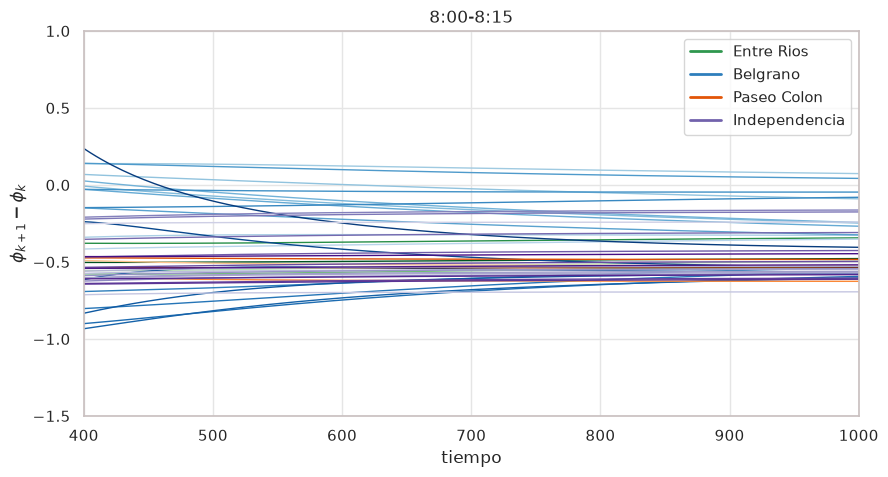

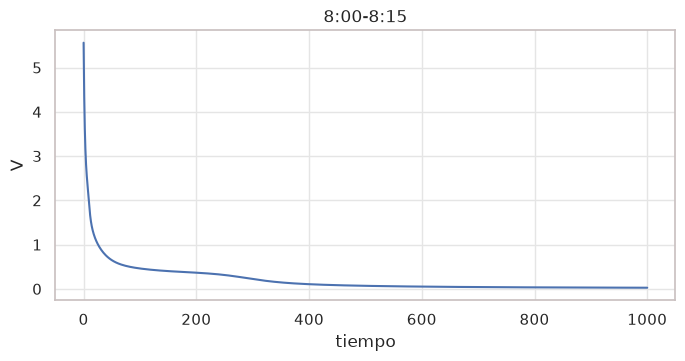

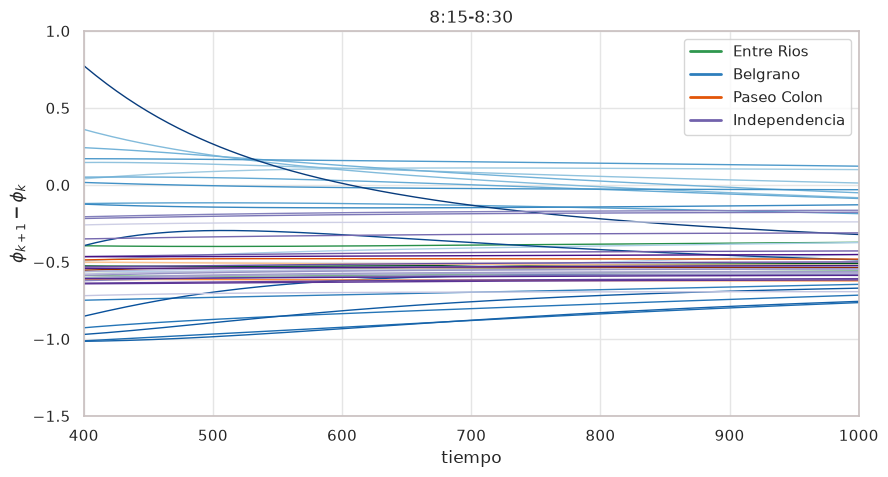

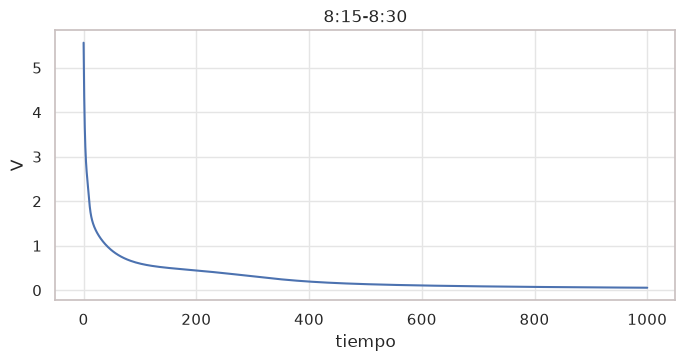

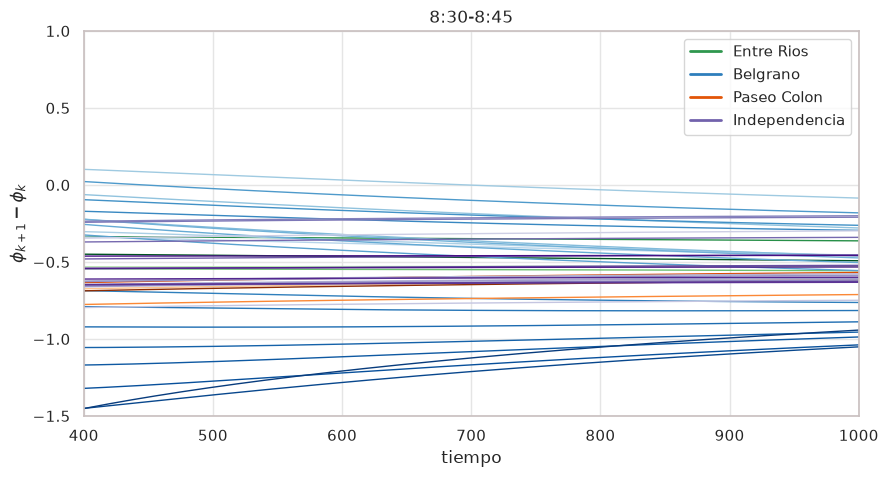

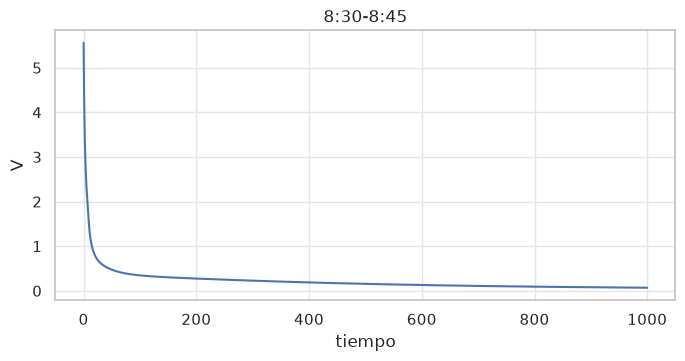

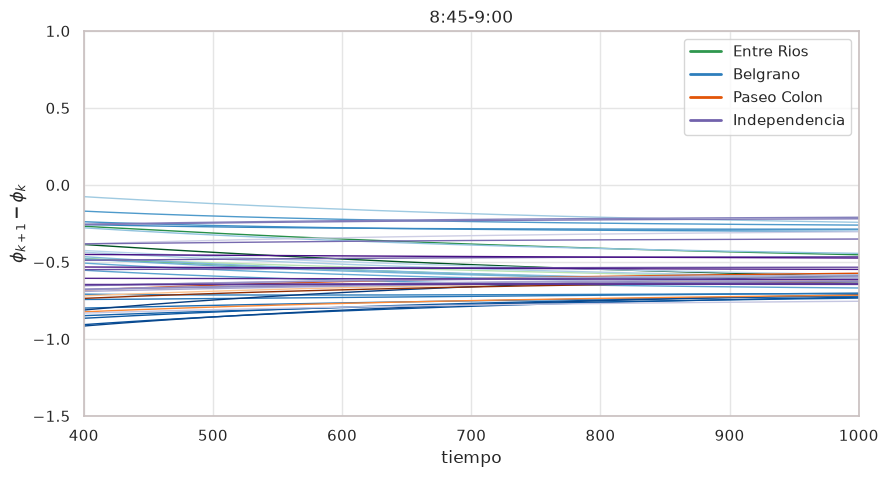

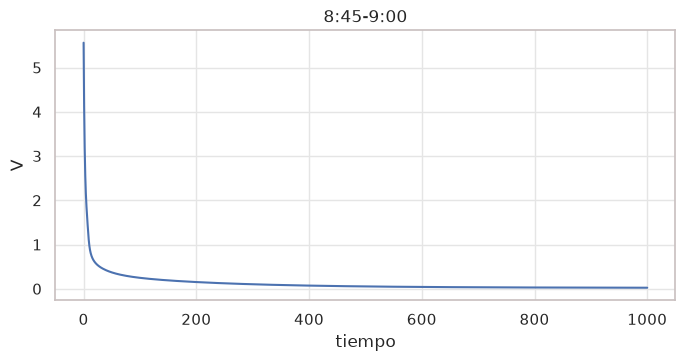

'# offset logrado menos offset objetivo en cada tramo\n    err = np.array([wrap(phi_f[k] - phi_f[(k+1) % n] - Delta[k, (k+1) % n]) for k in range(n)])\n    vel = np.abs(ecuaciones(0, phi_f, A, K, Delta)).max()   # ~0 si convergió\n    resultados[cuarto] = dict(K=K, t=t, y=y, err=err)\n    print(cuarto, "| max|dphi/dt| = %.1e" % vel,\n          "| error medio = %.3f rad" % np.abs(err).mean(),\n          "| error max = %.3f rad" % np.abs(err).max())'

In [9]:
#################################################################
############  circuito: Entre Ríos -> Belgrano -> Paseo Colón -> Independencia

from matplotlib.lines import Line2D

# --- supuestos míos, cambialos si tenés los reales ---
T_CICLO = 90.0     # s, ciclo común de todos los semáforos
V_KMH   = 60.0     # km/h, velocidad de marcha
T_SIM   = 1000     # tiempo de simulación

# --- distancia [m] del semáforo k al k+1 (el último cierra el circuito) ---
dist = np.array([121, 131, 88,                                                          # Entre Ríos
                 122, 125, 129, 43, 90, 132, 131, 132, 136, 36, 43, 37,
                 134, 131, 133, 134, 128, 129, 124,                                     # Belgrano
                 94, 125, 149, 115,                                                     # Paseo Colón
                 128, 57, 165, 130, 125, 135, 133, 129, 137, 38, 41, 73,
                 101, 118, 144, 146, 139, 124, 107])                                    # Independencia (el último vuelve al inicio)
n = len(dist)   # 45 semáforos: nodo k = orden k+1 de tu tabla

# calle por la que va cada tramo k -> k+1
calle = ["Entre Rios"]*4 + ["Belgrano"]*19 + ["Paseo Colon"]*4 + ["Independencia"]*18

# --- flujos [veh/15 min] de cada sensor, por cuarto de hora ---
flujos = {
    "8:00-8:15": {"Belgrano": 14.0, "Entre Rios": 57.6, "Independencia": 233.0, "Paseo Colon": 193.6},
    "8:15-8:30": {"Belgrano": 7.0,  "Entre Rios": 59.2, "Independencia": 242.0, "Paseo Colon": 180.4},
    "8:30-8:45": {"Belgrano": 32.6, "Entre Rios": 68.2, "Independencia": 269.0, "Paseo Colon": 192.2},
    "8:45-9:00": {"Belgrano": 96.4, "Entre Rios": 67.8, "Independencia": 282.8, "Paseo Colon": 206.2},
}

# --- matriz de adyacencia: anillo de 45 nodos ---
A = np.zeros((n, n))
for k in range(n):
    A[k, (k+1) % n] = 1
    A[(k+1) % n, k] = 1

# --- Delta = 2*pi*L/(T*v) entre semáforos consecutivos ---
v = V_KMH / 3.6
Delta = np.zeros((n, n))
for k in range(n):
    k2 = (k+1) % n
    Delta[k, k2] = Delta[k2, k] = (2*np.pi*dist[k]/(T_CICLO*v)) % (2*np.pi)

# --- matriz de pesos K: solo en el sentido de circulación (k -> k+1) ---
K_max = max(max(f.values()) for f in flujos.values())   # mismo escalado para los 4 casos

def matriz_K(f):
    K = np.zeros((n, n))
    for k in range(n):
        K[k, (k+1) % n] = f[calle[k]] / K_max
    return K

def wrap(x):
    return (x + np.pi) % (2*np.pi) - np.pi

colores_calle = {"Entre Rios":    plt.cm.Greens,
                 "Belgrano":      plt.cm.Blues,
                 "Paseo Colon":   plt.cm.Oranges,
                 "Independencia": plt.cm.Purples}

def potencial(phi, A, K, Delta):
    # V = sum_i (1/d) sum_{j vecino de i} (1/2) K_ji (1 - cos(phi_j - phi_i - Delta_ji))
    n = len(phi)                            # cantidad de nodos
    d = A[0].sum()                          # grado (es el mismo para todos)
    V = 0.0                                 # acumulador
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # pero solo suma si j es vecino de i
                V += (1 / d) * 0.5 * K[j, i] * (1 - np.cos(phi[j] - phi[i] - Delta[j, i]))
    return V


def graficar_fases(t, y, titulo=""):
    n = len(y)
    fig, ax = plt.subplots(figsize=(10, 5))
    for nombre, cmap in colores_calle.items():
        ks = [k for k in range(n) if calle[k] == nombre]    # tramos de la avenida, en orden
        tonos = np.linspace(0.3, 0.95, len(ks))              # claro -> oscuro
        for k, tono in zip(ks, tonos):
            d = y[(k+1) % n] - y[k]
            d = d - 2*np.pi*np.round(d[-1]/(2*np.pi))        # todas en el mismo ciclo de 2*pi
            ax.plot(t, d, color=cmap(tono), lw=1)
    ax.legend(handles=[Line2D([0], [0], color=c(0.7), lw=2, label=nom)
                       for nom, c in colores_calle.items()], loc="upper right")
    ax.set_xlabel("tiempo")
    ax.set_ylabel(r"$\phi_{k+1}-\phi_k$")
    ax.set_title(titulo)
    ax.set_xlim(400, 1000)
    ax.set_ylim(-1.5, 1)
    plt.show()

    V = np.array([potencial(y[:, f], A, K, Delta) for f in range(len(t))])
    plt.figure(figsize=(8, 3.5))
    plt.plot(t, V)
    plt.xlabel("tiempo")
    plt.ylabel("V")
    plt.title(titulo)
    plt.show()


# --- simular los 4 casos ---
resultados = {}

for cuarto, f in flujos.items():
    K = matriz_K(f)
    phi0 = condiciones_iniciales_random(n, semilla=0) 
    t, y = simular(phi0, A, K, Delta, T_SIM)
    resultados[cuarto] = dict(K=K, t=t, y=y)


# --- graficar los 4 casos ---
for cuarto, r in resultados.items():
    graficar_fases(r["t"], r["y"], cuarto)




'''# offset logrado menos offset objetivo en cada tramo
    err = np.array([wrap(phi_f[k] - phi_f[(k+1) % n] - Delta[k, (k+1) % n]) for k in range(n)])
    vel = np.abs(ecuaciones(0, phi_f, A, K, Delta)).max()   # ~0 si convergió
    resultados[cuarto] = dict(K=K, t=t, y=y, err=err)
    print(cuarto, "| max|dphi/dt| = %.1e" % vel,
          "| error medio = %.3f rad" % np.abs(err).mean(),
          "| error max = %.3f rad" % np.abs(err).max())'''

# Animacion 

In [10]:
import matplotlib.animation as animation
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 100      # MB, si no corta la animación

#################################################################
############  animación del circuito

CUARTO   = "8:00-8:15"   # qué caso de flujo usar
T_ANIM   = 1200          # s simulados
DT_FRAME = 3             # s entre cuadros
SEMILLA  = 0             # None = otra condición inicial cada vez
VERDE    = 0.5           # fracción del ciclo en verde

# --- posición de cada semáforo (lat, lon de tu tabla, orden 1..45) ---
latlon = np.array([
    [-34.618148, -58.391692], [-34.616867, -58.391678], [-34.615690, -58.391660], [-34.614899, -58.391677],
    [-34.613808, -58.391723], [-34.613716, -58.390365], [-34.613619, -58.388961], [-34.613587, -58.388498],
    [-34.613524, -58.387521], [-34.613428, -58.386082], [-34.613319, -58.384657], [-34.613211, -58.383226],
    [-34.613119, -58.381747], [-34.613090, -58.381360], [-34.613056, -58.380892], [-34.613030, -58.380487],
    [-34.612938, -58.379030], [-34.612870, -58.377605], [-34.612754, -58.376163], [-34.612645, -58.374707],
    [-34.612536, -58.373318], [-34.612452, -58.371918], [-34.612373, -58.370567], [-34.612328, -58.369547],
    [-34.613443, -58.369333], [-34.614782, -58.369468], [-34.615818, -58.369460], [-34.616965, -58.369434],
    [-34.617143, -58.369870], [-34.617187, -58.371673], [-34.617165, -58.373087], [-34.617243, -58.374450],
    [-34.617346, -58.375918], [-34.617445, -58.377367], [-34.617536, -58.378776], [-34.617628, -58.380264],
    [-34.617627, -58.380676], [-34.617635, -58.381128], [-34.617659, -58.381921], [-34.617727, -58.383019],
    [-34.617779, -58.384310], [-34.617837, -58.385875], [-34.617899, -58.387467], [-34.617993, -58.388978],
    [-34.618072, -58.390332]])
lat0, lon0 = latlon[:, 0].mean(), latlon[:, 1].mean()
px = (latlon[:, 1] - lon0) * 111320 * np.cos(np.radians(lat0))    # metros
py = (latlon[:, 0] - lat0) * 110540

# --- simular desde una condición inicial arbitraria ---
K = matriz_K(flujos[CUARTO])
phi0 = condiciones_iniciales_random(n, SEMILLA)
t_frames = np.arange(0, T_ANIM, DT_FRAME)
sol = solve_ivp(ecuaciones, (0, T_ANIM), phi0, args=(A, K, Delta, 0.0),
                t_eval=t_frames, rtol=1e-8, atol=1e-10)

# la simulación está en el sistema que rota con omega; para ver los semáforos se la devuelvo
omega = 2*np.pi/T_CICLO
fase_real = sol.y + omega*sol.t
verde = (fase_real % (2*np.pi)) < VERDE*2*np.pi      # True = verde, False = rojo

# --- dibujo ---
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(np.append(px, px[0]), np.append(py, py[0]), color="lightgray", lw=3, zorder=1)
sc = ax.scatter(px, py, s=80, edgecolor="black", zorder=2)
ax.set_aspect("equal")
ax.axis("off")
titulo = ax.set_title("")

def actualizar(f):
    sc.set_facecolor(list(np.where(verde[:, f], "limegreen", "red")))
    titulo.set_text(f"{CUARTO}  |  t = {sol.t[f]:.0f} s")
    return sc, titulo

anim = animation.FuncAnimation(fig, actualizar, frames=len(sol.t), interval=40, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())